In [1]:
# Block 1
%load_ext autoreload
%autoreload 1

# Watch the modules these cells call into
%aimport utility
%aimport config
%aimport faster_rcnn_detector

import numpy as np
import pandas as pd

import torch

import config
import utility

from faster_rcnn_detector import FasterRCNN

In [2]:
# Block 2
LESION_TYPE = "mass"
# LESION_TYPE = "calc"

# Seed python, numpy and torch, and pin the cuDNN algorithm
utility.set_deterministic()

config.FASTER_RCNN_WORKSPACE.mkdir(parents=True, exist_ok=True)
config.MODELS_ROOT.mkdir(parents=True, exist_ok=True)

device = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"

print(f"Device       : {device}")
print(f"Lesion type  : {LESION_TYPE}")
print(f"Frame        : long side {config.FASTER_RCNN_RESIZE} px")
print(f"Classes      : {config.CLASS_NAMES}")
print(f"Folds        : {config.OOF_FOLDS}")
print(f"Workspace    : {config.FASTER_RCNN_WORKSPACE}")
print(f"Models       : {config.MODELS_ROOT}")

Device       : NVIDIA GeForce RTX 3060 Laptop GPU
Lesion type  : mass
Frame        : long side 768 px
Classes      : ('benign', 'malignant')
Folds        : (0, 1, 2, 3, 4)
Workspace    : C:\Users\User\Desktop\sch work\fyp\02_faster_rcnn_workspace
Models       : C:\Users\User\Desktop\sch work\fyp\models


In [3]:
# Block 3
# Load metadata
metadata = pd.read_csv(config.PROJECT_ROOT / f"{LESION_TYPE}_metadata.csv")

display(metadata.head())

print(f"Rows: {len(metadata):,}")
print(f"Unique mammograms: {metadata['full_image'].nunique():,}")
print(f"Unique lesions: {metadata['mask_image'].nunique():,}")

,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,...,split,fold,full_image,crop_image,mask_image,breast_mask,breast_xmin,breast_ymin,breast_xmax,breast_ymax
0,P_00016,4,LEFT,CC,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,...,test,-1,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,198,0,471,1023
1,P_00016,4,LEFT,MLO,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,...,test,-1,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,0,0,374,1023
2,P_00017,2,LEFT,CC,1,mass,ROUND,CIRCUMSCRIBED,4,MALIGNANT,...,trainval,0,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,0,0,554,1023
3,P_00017,2,LEFT,MLO,1,mass,ROUND,ILL_DEFINED,4,MALIGNANT,...,trainval,0,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,0,0,576,1023
4,P_00032,3,RIGHT,CC,1,mass,ROUND,OBSCURED,0,BENIGN,...,trainval,2,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,C:\Users\User\Desktop\sch work\fyp\dataset\mas...,153,0,528,1023


Rows: 1,696
Unique mammograms: 1,592
Unique lesions: 1,696


In [4]:
# Block 4
# Per-mammogram split, then the fold 0 validation set
groups = utility.group_mammograms(metadata)

# Out-of-fold predictions cover the trainval split only; test stays held out
trainval_df = groups[groups["split"] == "trainval"].reset_index(drop=True)
test_df = groups[groups["split"] == "test"].reset_index(drop=True)

train_df, val_df = utility.oof_split(trainval_df, config.VAL_FOLD)

print(f"Trainval: {len(trainval_df):,} mammograms, folds {trainval_df['fold'].value_counts().sort_index().to_dict()}")
print(f"Test    : {len(test_df):,} mammograms, held out")
print(f"Fold {config.VAL_FOLD}: train {len(train_df):,}, val {len(val_df):,}")

Trainval: 1,272 mammograms, folds {0: 264, 1: 248, 2: 248, 3: 253, 4: 259}
Test    : 320 mammograms, held out
Fold 0: train 1,008, val 264


In [5]:
# Block 5
# Prepare one sample through the Faster R-CNN pipeline
faster_rcnn = FasterRCNN()

image, boxes, class_labels = faster_rcnn.prepare(trainval_df.iloc[0])

counts = np.bincount(class_labels, minlength=config.CLASS_COUNT)

print(f"Frame     : {image.shape}")
print(f"GT boxes  : {len(boxes)}")
print(f"Classes   : " + ", ".join(f"{name} {count}" for name, count in zip(config.CLASS_NAMES, counts)))
print(f"Box bounds: {boxes.min(axis=0).round(1).tolist()} to {boxes.max(axis=0).round(1).tolist()}")

# Torchvision reserves label 0 for background, so every class target shifts by one
print(f"Labels    : {sorted(set((class_labels + 1).tolist()))} inside 1..{config.FASTER_RCNN_CLASS_COUNT - 1}")

Frame     : (768, 416)
GT boxes  : 1
Classes   : benign 0, malignant 1
Box bounds: [33.0, 490.5, 52.5, 512.2000122070312] to [33.0, 490.5, 52.5, 512.2000122070312]
Labels    : [2] inside 1..2


In [6]:
# Block 6
# Inspect one augmented training batch
train_loader = faster_rcnn.loaders(train_df, shuffle=True, augment=True)
train_dataset = train_loader.dataset

image, target = train_dataset[0]

print(f"Image shape   : {tuple(image.shape)}")
print(f"Labels        : {sorted(set(target['labels'].tolist()))}")
print(f"GT boxes      : {len(target['boxes'])}")
print(f"Train images  : {len(train_dataset):,}")
print(f"Train batches : {len(train_loader):,}")

Image shape   : (3, 768, 397)
Labels        : [1]
GT boxes      : 1
Train images  : 1,008
Train batches : 63


In [7]:
# Block 7
# Build the model and print its summary
faster_rcnn.build()
faster_rcnn.summary()

Total     : 18,935,354
Trainable : 18,876,458


{'total': 18935354, 'trainable': 18876458}

In [8]:
# Block 8
# One model per fold; a completed fold is skipped, so re-running resumes the rest
print("Loss     : torchvision multi-task, obj/box/cls/rpn summed")
print(
    f"Schedule : SGD {config.FASTER_RCNN_LR}, plateau x{config.LR_FACTOR} after {config.LR_PATIENCE} epochs, "
    f"{config.FASTER_RCNN_NUM_EPOCHS} epochs total"
)
print(
    f"Export   : stacker floor {config.FASTER_RCNN_STACKER_SCORE_THRESHOLD}, "
    f"top {config.FASTER_RCNN_STACKER_TOP_K} per image"
)


oof_summary = {}

for fold in config.OOF_FOLDS:
    oof_summary[fold] = faster_rcnn.oof_fold(trainval_df, fold, LESION_TYPE, export=False)

# Export each fold's records and its ranked candidate feed for the stacker
exported = faster_rcnn.export_folds(trainval_df, LESION_TYPE)

pd.DataFrame.from_dict(exported, orient="index")

Loss     : torchvision multi-task, obj/box/cls/rpn summed
Schedule : SGD 0.001, plateau x0.5 after 4 epochs, 50 epochs total
Export   : stacker floor 0.05, top 100 per image
Fold 0: complete (val AP50 0.5560, 1162 records), skipping
Epoch | Loss   | obj    | box    | cls    | rpn    | AP50   | mAP50  | P      | R      | F1     | Det
1     | 0.2630 | 0.0493 | 0.0344 | 0.1739 | 0.0054 | 0.0018 | 0.0008 | 0.0000 | 0.0000 | 0.0000 | 0.0
2     | 0.1512 | 0.0247 | 0.0441 | 0.0780 | 0.0044 | 0.0428 | 0.0308 | 0.0000 | 0.0000 | 0.0000 | 0.0
3     | 0.1858 | 0.0216 | 0.0656 | 0.0946 | 0.0041 | 0.1303 | 0.1100 | 0.0000 | 0.0000 | 0.0000 | 0.0
4     | 0.2321 | 0.0183 | 0.0920 | 0.1182 | 0.0037 | 0.2201 | 0.1716 | 0.0000 | 0.0000 | 0.0000 | 0.0
5     | 0.2566 | 0.0168 | 0.1060 | 0.1303 | 0.0036 | 0.2707 | 0.2130 | 0.5714 | 0.0285 | 0.0542 | 0.1
6     | 0.2961 | 0.0153 | 0.1278 | 0.1494 | 0.0036 | 0.3031 | 0.2455 | 0.7447 | 0.1246 | 0.2134 | 0.2
7     | 0.3140 | 0.0150 | 0.1357 | 0.1599 | 0.0034 | 

,fold,seed,epochs,best_epoch,best_val_ap50,record_count,image_count,fingerprint,candidate_count,exported
0,0,42,50,37,0.556031,1162,264,c3d5798de593,10954,True
1,1,42,50,30,0.455217,851,248,c3d5798de593,9890,True
2,2,42,50,44,0.524361,873,248,c3d5798de593,10142,True
3,3,42,50,34,0.532491,1281,253,c3d5798de593,11695,True
4,4,42,50,43,0.547831,774,259,c3d5798de593,9231,True


In [9]:
# Block 9
# Coverage check: each fold's records stay inside their own fold and no test mammogram appears
fold_records_paths = {fold: config.fold_paths("faster_rcnn", LESION_TYPE, fold)["records"] for fold in config.OOF_FOLDS}

records_by_fold = utility.oof_records(fold_records_paths)
manifest = utility.read_oof_manifest(config.oof_manifest_path("faster_rcnn", LESION_TYPE))

print(f"Folds complete: {sorted(manifest['folds'])}")

trainval_ids = pd.Series([utility.mammogram_id(path) for path in trainval_df["full_image"]], index=trainval_df.index)
test_ids = {utility.mammogram_id(path) for path in test_df["full_image"]}

covered = []

for fold, frame in records_by_fold.items():
    fold_ids = set(frame["image_id"])
    expected_ids = set(trainval_ids[trainval_df["fold"] == fold])

    covered.extend(sorted(fold_ids))

    print(
        f"Fold {fold}: {frame['image_id'].nunique():,} mammograms, {len(frame):,} records, "
        f"outside its own fold: {len(fold_ids - expected_ids)}, "
        f"images with detections: {len(fold_ids)}/{len(expected_ids)}"
    )

print(f"OOF mammograms: {len(covered):,} rows, {len(set(covered)):,} unique of {len(trainval_df):,} trainval")
print(f"Test mammograms inside the OOF records: {len(set(covered) & test_ids)}")

Folds complete: ['0', '1', '2', '3', '4']
Fold 0: 255 mammograms, 1,162 records, outside its own fold: 0, images with detections: 255/264
Fold 1: 239 mammograms, 851 records, outside its own fold: 0, images with detections: 239/248
Fold 2: 237 mammograms, 873 records, outside its own fold: 0, images with detections: 237/248
Fold 3: 249 mammograms, 1,281 records, outside its own fold: 0, images with detections: 249/253
Fold 4: 249 mammograms, 774 records, outside its own fold: 0, images with detections: 249/259
OOF mammograms: 1,229 rows, 1,229 unique of 1,272 trainval
Test mammograms inside the OOF records: 0


In [10]:
# Block 10
# Fold manifest table
manifest_df = pd.DataFrame.from_dict(manifest["folds"], orient="index").sort_index()
manifest_df.index.name = "fold"

display(manifest_df)

,fold,seed,epochs,best_epoch,best_val_ap50,record_count,image_count,fingerprint,candidate_count,exported
fold,,,,,,,,,,
0,0,42,50,37,0.556031,1162,264,c3d5798de593,10954,True
1,1,42,50,30,0.455217,851,248,c3d5798de593,9890,True
2,2,42,50,44,0.524361,873,248,c3d5798de593,10142,True
3,3,42,50,34,0.532491,1281,253,c3d5798de593,11695,True
4,4,42,50,43,0.547831,774,259,c3d5798de593,9231,True


infer:   0%|          | 0/17 [00:00<?, ?it/s]

Fold 0: 264 mammograms


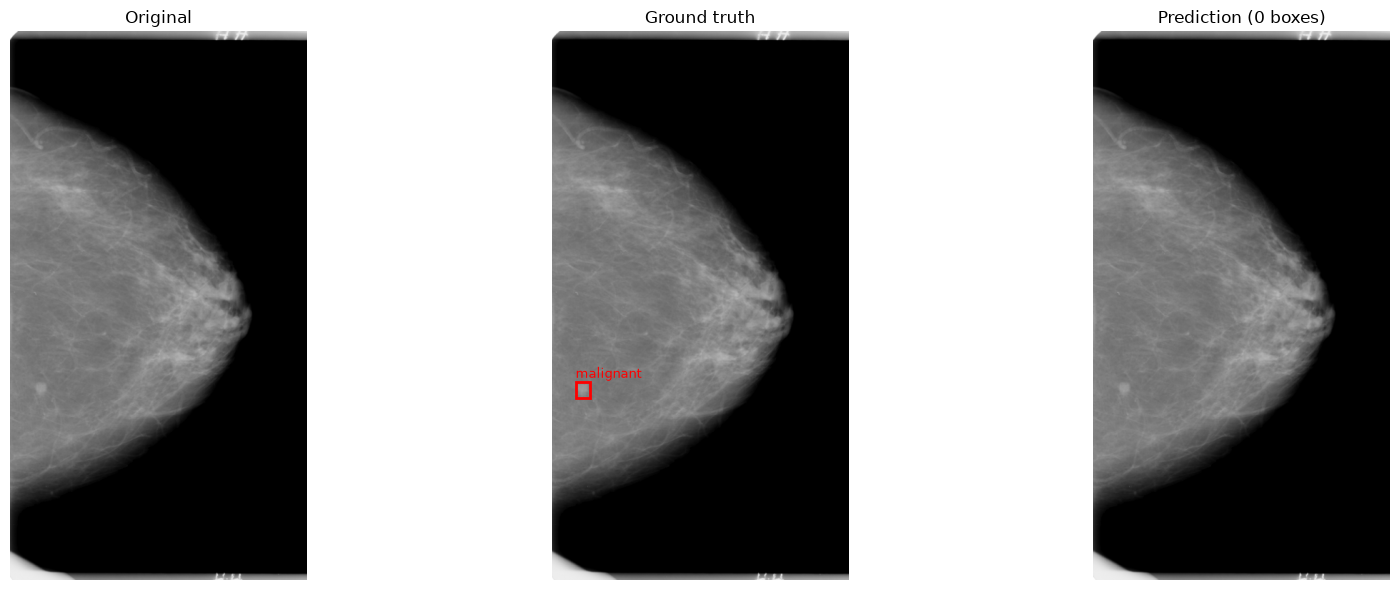

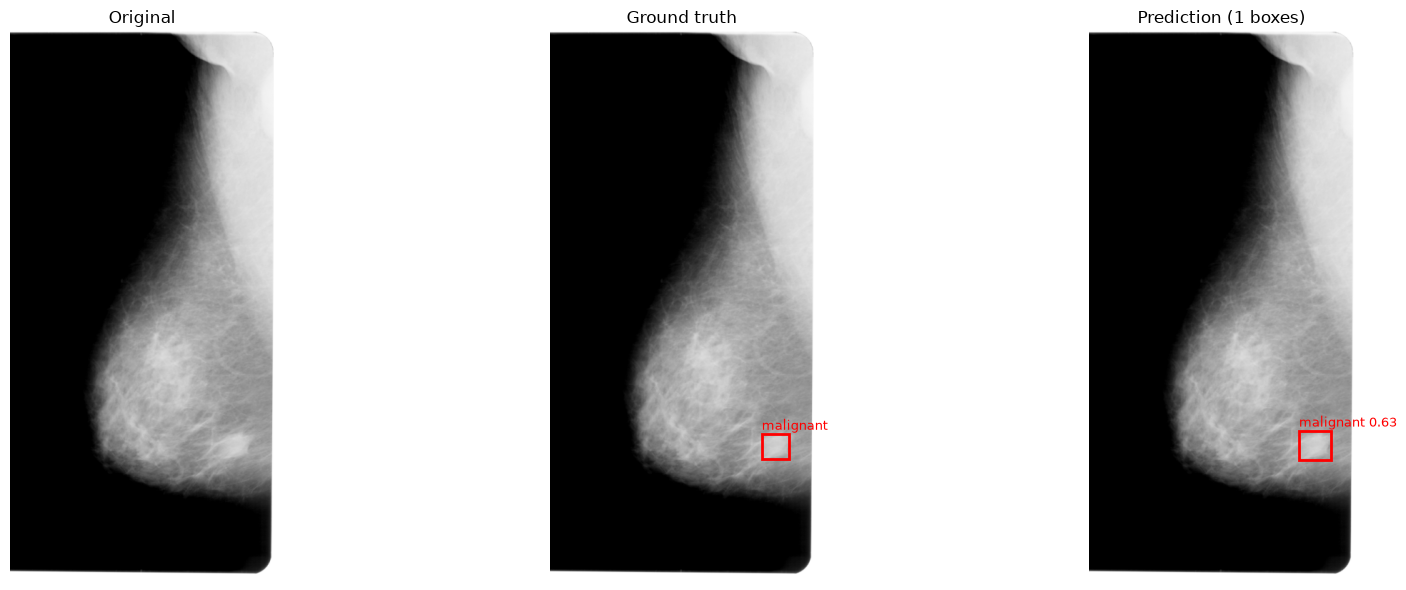

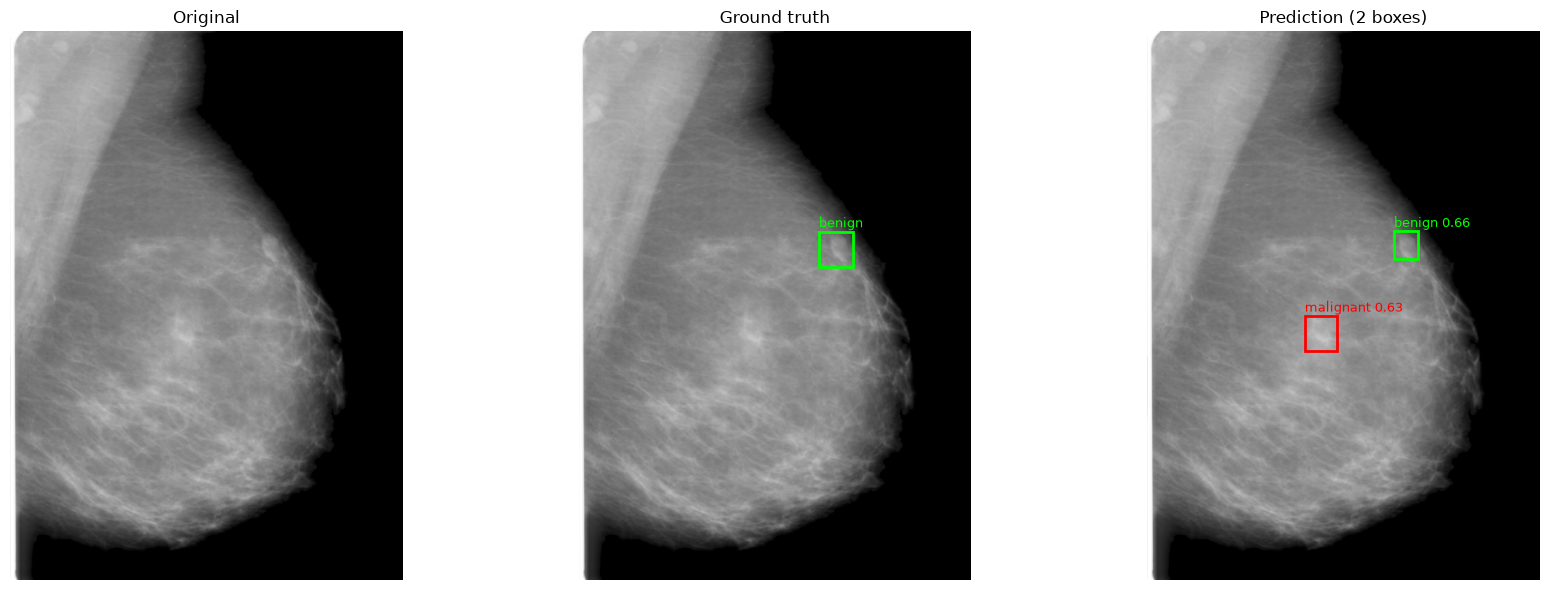

infer:   0%|          | 0/16 [00:00<?, ?it/s]

Fold 1: 248 mammograms


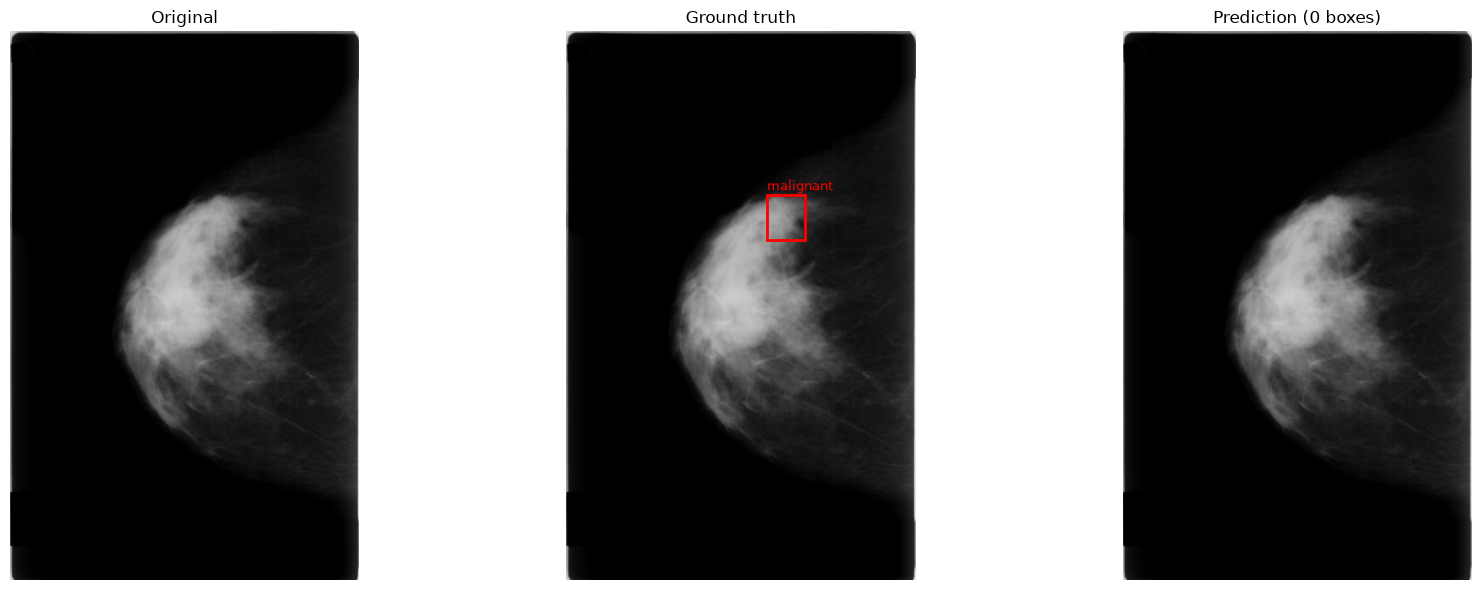

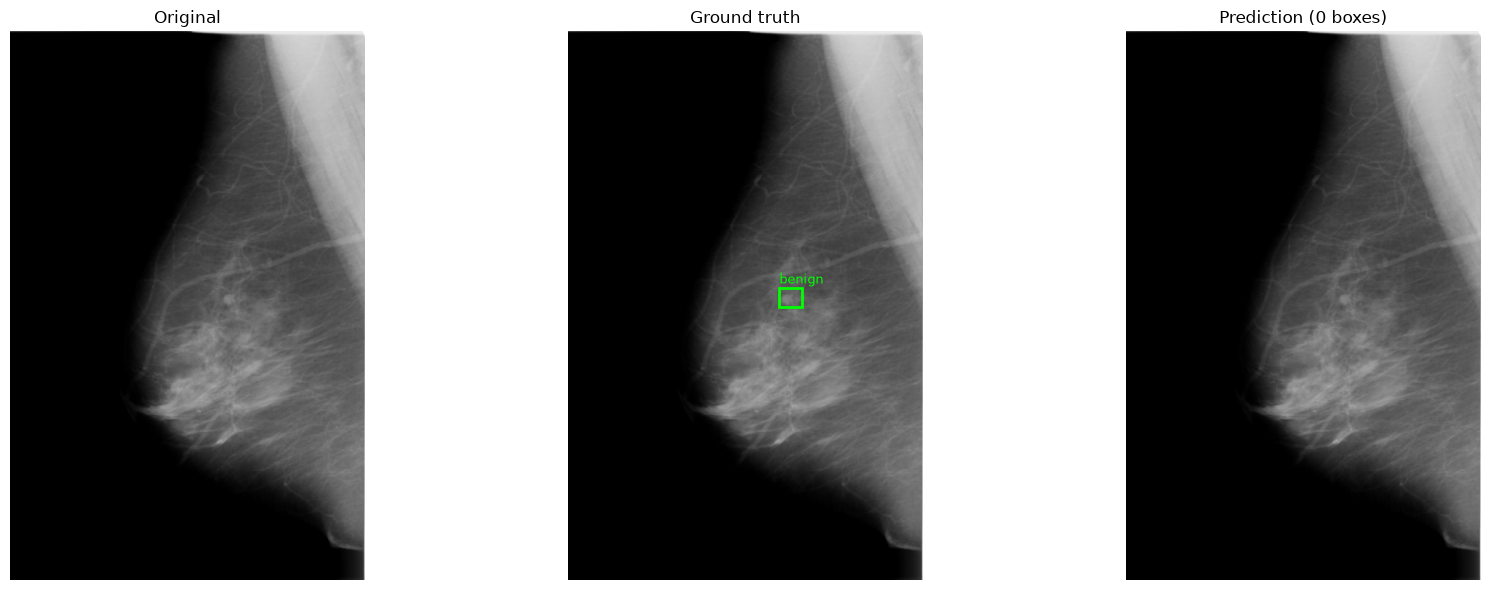

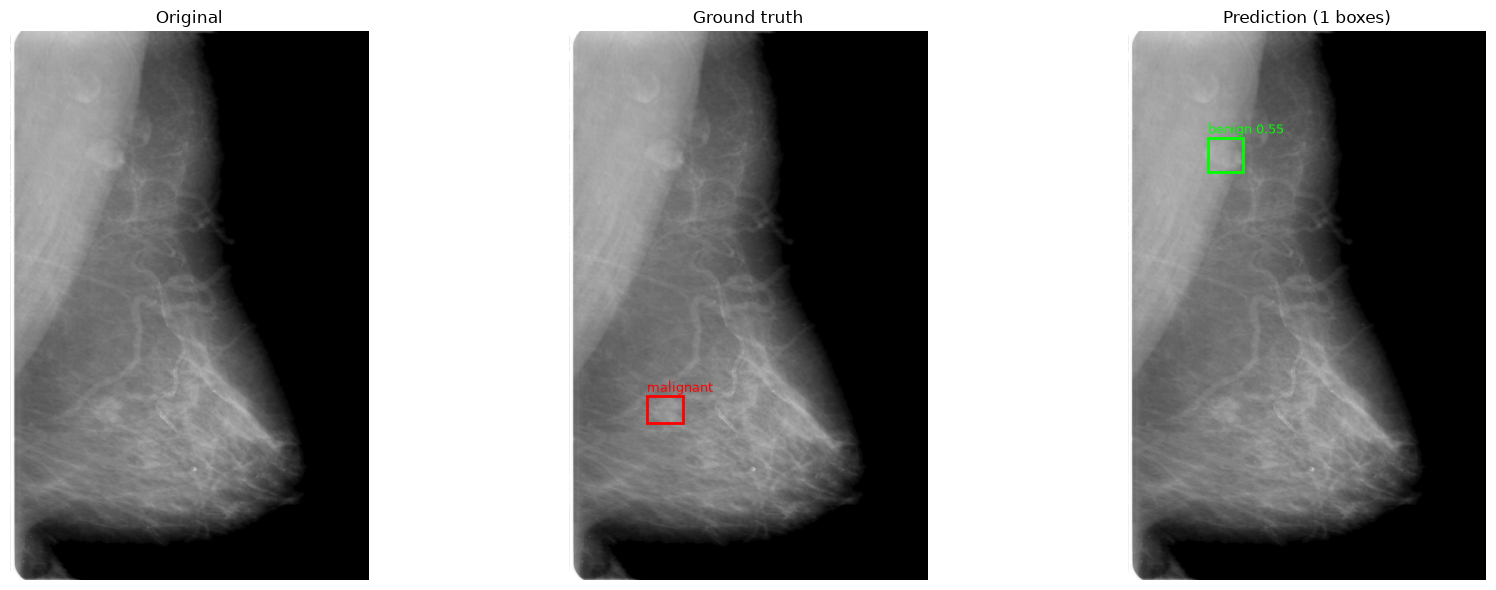

infer:   0%|          | 0/16 [00:00<?, ?it/s]

Fold 2: 248 mammograms


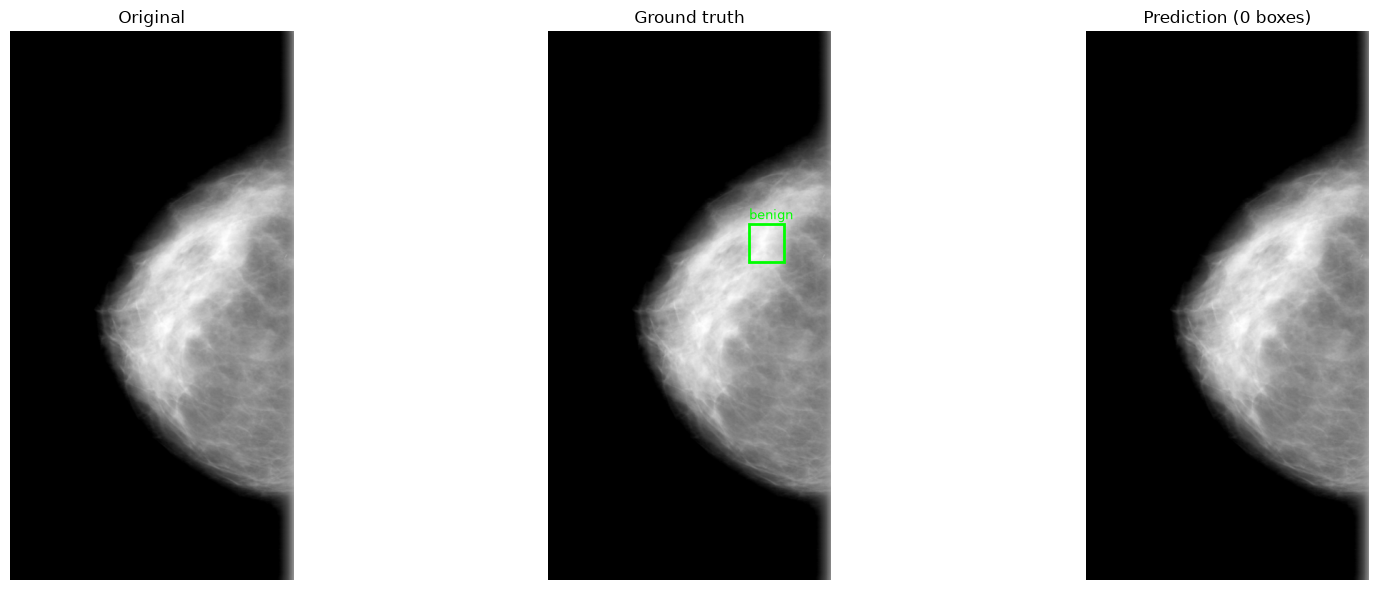

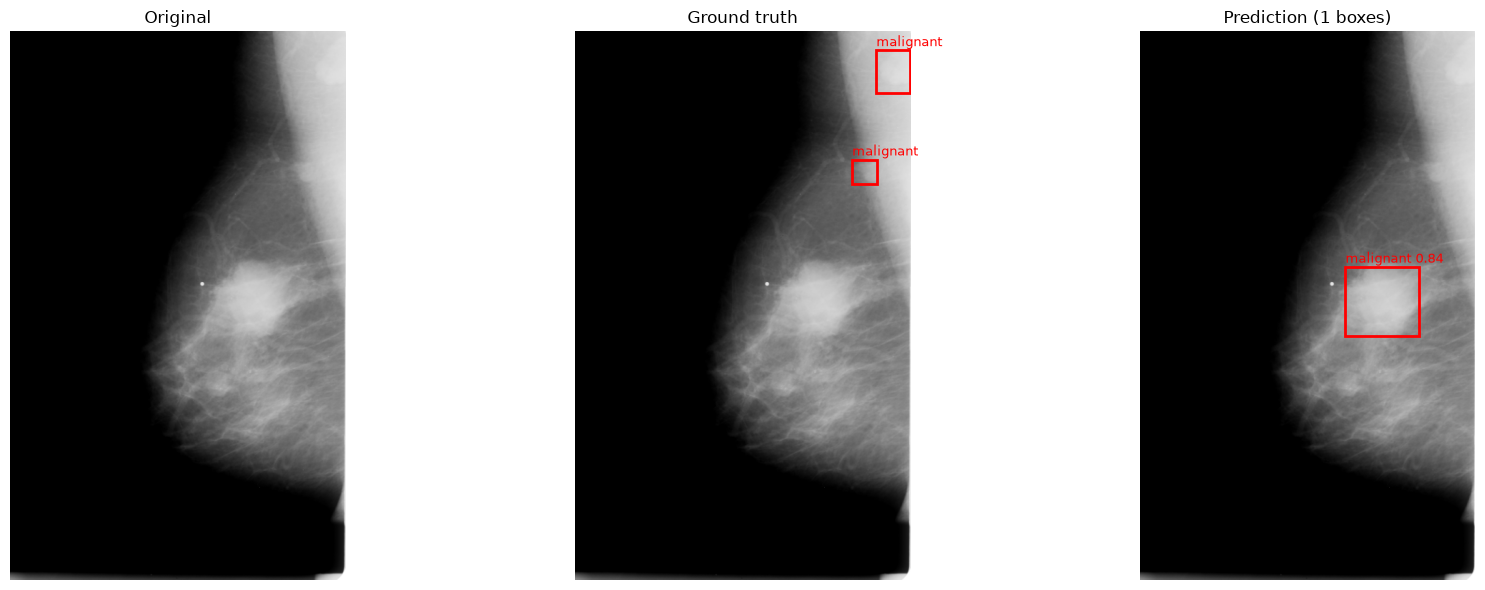

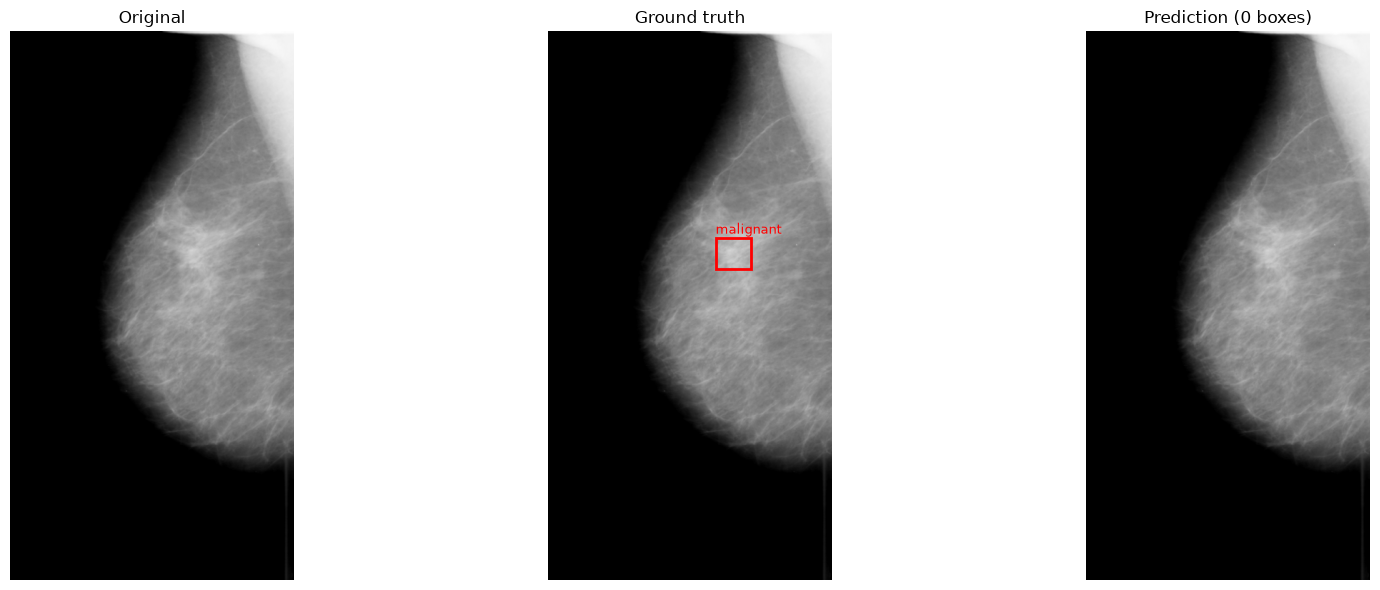

infer:   0%|          | 0/16 [00:00<?, ?it/s]

Fold 3: 253 mammograms


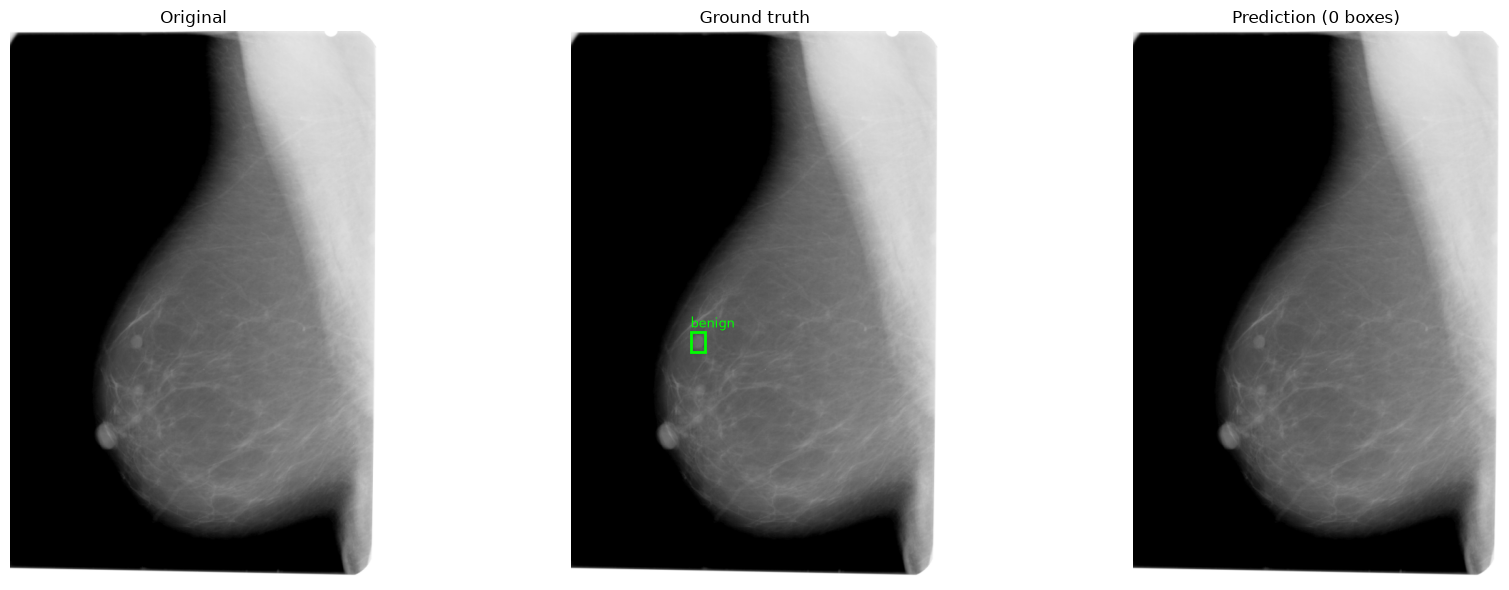

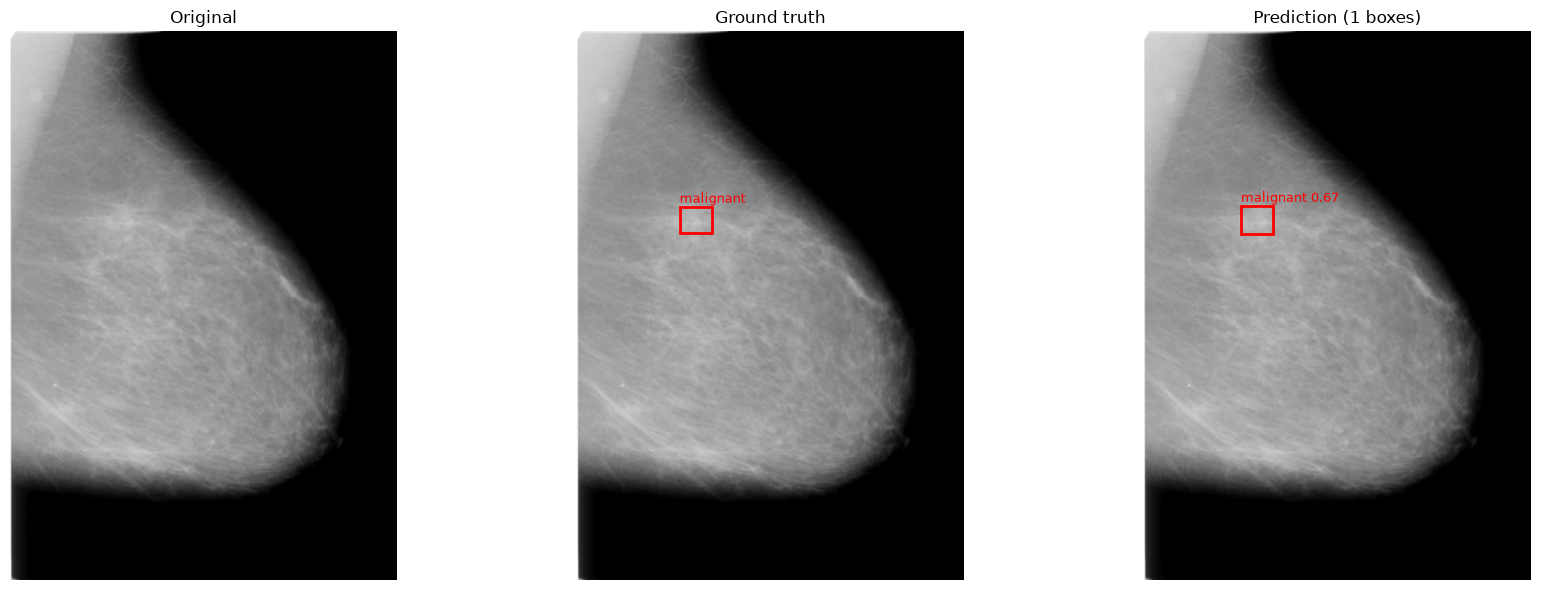

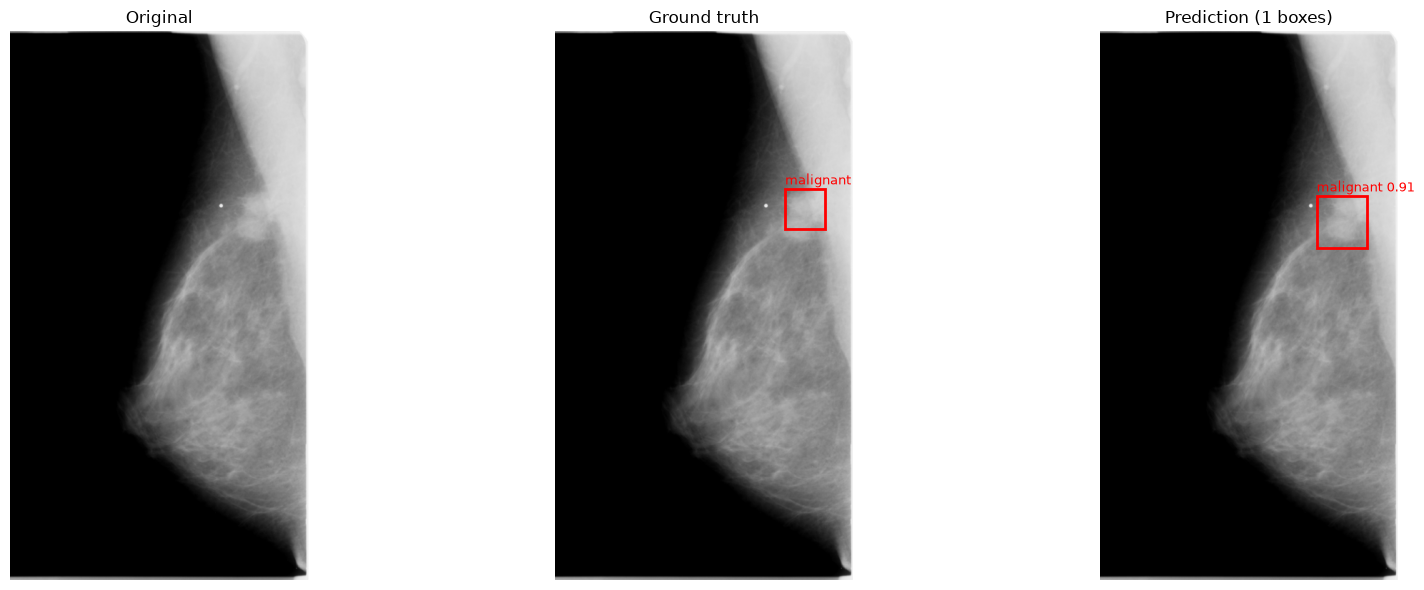

infer:   0%|          | 0/17 [00:00<?, ?it/s]

Fold 4: 259 mammograms


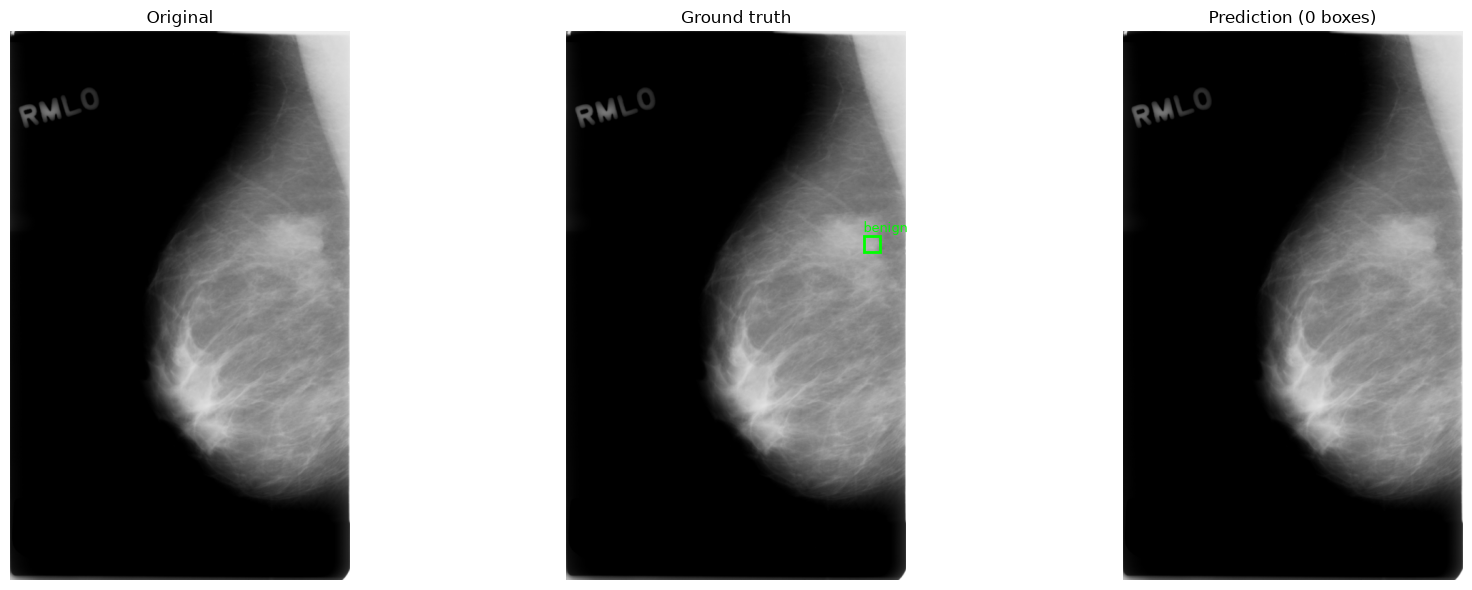

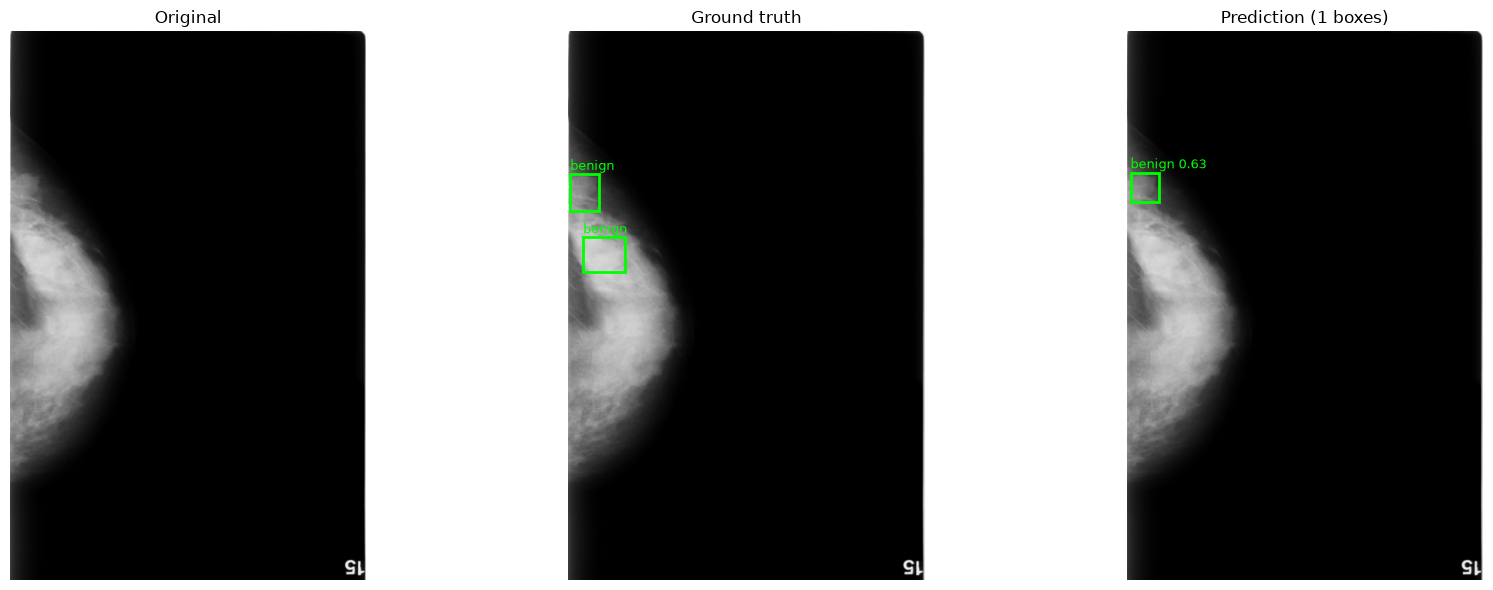

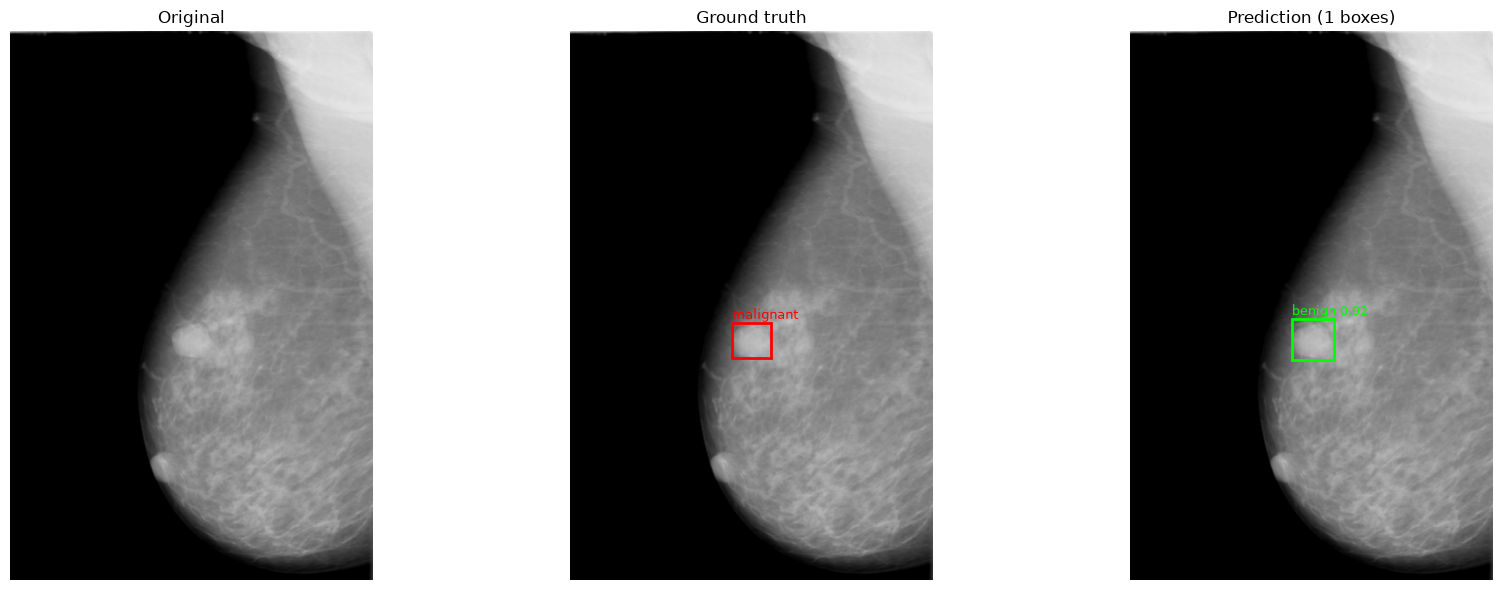

In [11]:
# Block 11
# Qualitative check: three held-out mammograms per fold at the operating threshold
fold_predictions = {}

for fold in config.OOF_FOLDS:
    scorer = FasterRCNN(config.fold_model_path("faster_rcnn", LESION_TYPE, fold))
    scorer.load()

    val_fold_df = trainval_df[trainval_df["fold"] == fold].reset_index(drop=True)
    fold_predictions[fold] = scorer.infer(val_fold_df)

    print(f"Fold {fold}: {len(val_fold_df):,} mammograms")

    for index in np.linspace(0, len(val_fold_df) - 1, 3, dtype=int):
        image, gt_boxes, gt_labels, boxes, scores, labels = scorer.predict_image(val_fold_df.iloc[index])

        utility.visualize_detections(image, gt_boxes, gt_labels, boxes, scores, labels, config.CLASS_NAMES)

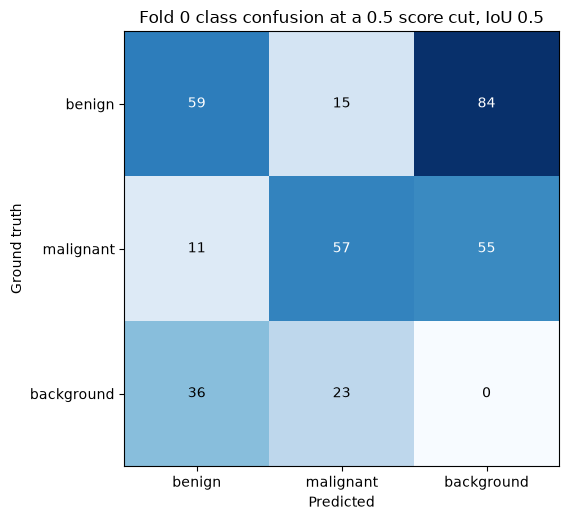

Fold 0
True positives  : 116
False negatives : 139
False positives : 59
Misclassified   : 26


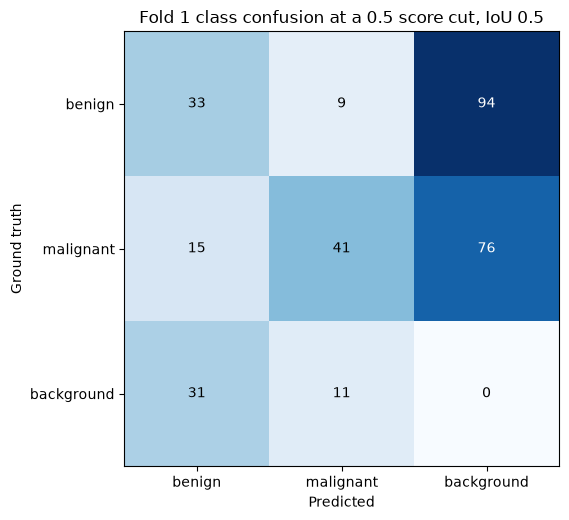

Fold 1
True positives  : 74
False negatives : 170
False positives : 42
Misclassified   : 24


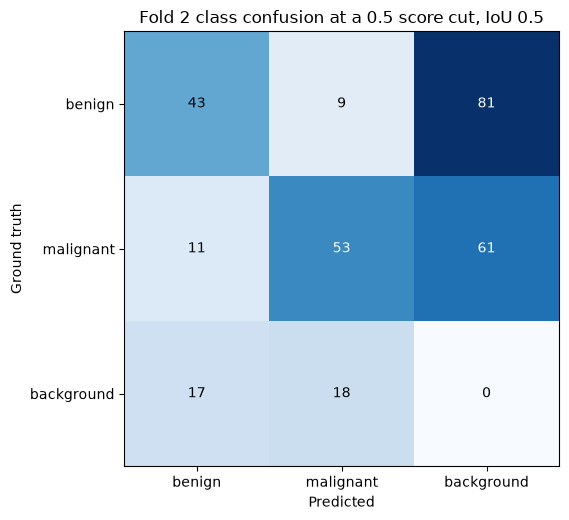

Fold 2
True positives  : 96
False negatives : 142
False positives : 35
Misclassified   : 20


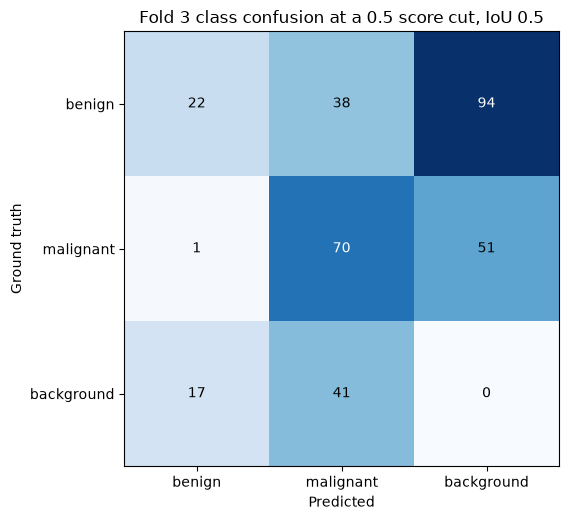

Fold 3
True positives  : 92
False negatives : 145
False positives : 58
Misclassified   : 39


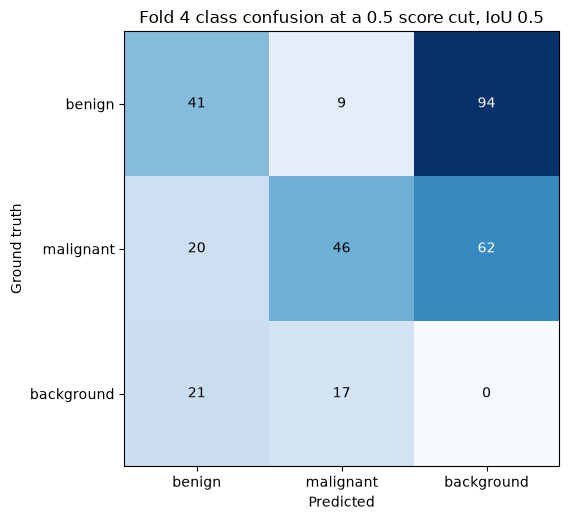

Fold 4
True positives  : 87
False negatives : 156
False positives : 38
Misclassified   : 29


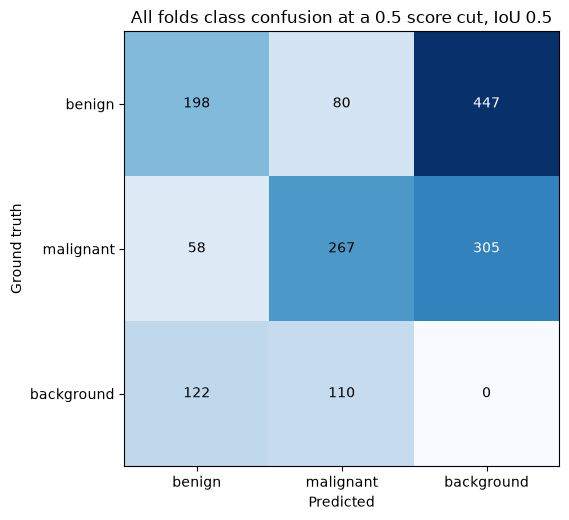

All folds
True positives  : 465
False negatives : 752
False positives : 232
Misclassified   : 138


In [12]:
# Block 12
# Class confusion per fold, plus the pooled matrix
classes = list(config.CLASS_NAMES)

fold_confusions = {
    fold: utility.detection_confusion(
        records, iou_threshold=config.FASTER_RCNN_IOU_THRESHOLD, class_names=config.CLASS_NAMES
    )
    for fold, records in fold_predictions.items()
}

confusions = {f"fold {fold}": frame for fold, frame in fold_confusions.items()}

# Pooling the per-fold matrices is the same as one confusion over every fold's records
confusions["all folds"] = sum(fold_confusions.values())

for name, confusion in confusions.items():
    utility.plot_confusion(
        confusion,
        title=(
            f"{name.capitalize()} class confusion at a {config.FASTER_RCNN_INFERENCE_SCORE_THRESHOLD} score cut, "
            f"IoU {config.FASTER_RCNN_IOU_THRESHOLD}"
        ),
    )

    true_positive = int(np.trace(confusion.loc[classes, classes].to_numpy()))
    false_negative = int(confusion.loc[classes, "background"].sum())
    false_positive = int(confusion.loc["background", classes].sum())
    misclassified = int(confusion.loc[classes, classes].to_numpy().sum() - true_positive)

    print(f"{name.capitalize()}")
    print(f"True positives  : {true_positive:,}")
    print(f"False negatives : {false_negative:,}")
    print(f"False positives : {false_positive:,}")
    print(f"Misclassified   : {misclassified:,}")

In [13]:
# Block 13
# The five held-out fold checkpoints above, against the single model retrained on all trainval
import final_retrain

fold_checkpoints = sorted(config.MODELS_ROOT.glob(f"{LESION_TYPE}_faster_rcnn_fold*.pt"))
full_model = final_retrain.load_or_train("faster_rcnn")

print(f"Fold ensemble: {len(fold_checkpoints)} checkpoints, {config.MODELS_ROOT}")
print(f"Full retrain : {full_model.name}, {full_model.stat().st_size / 1e6:.1f} MB")

faster_rcnn: mass_faster_rcnn_full.pt is already on disk, not retraining
Fold ensemble: 5 checkpoints, C:\Users\User\Desktop\sch work\fyp\models
Full retrain : mass_faster_rcnn_full.pt, 76.1 MB


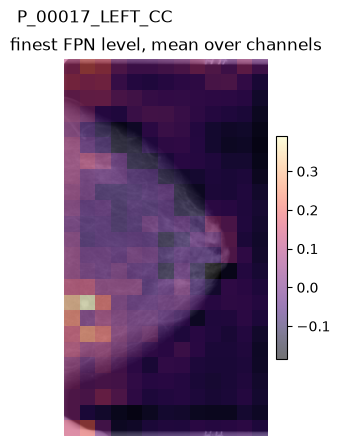

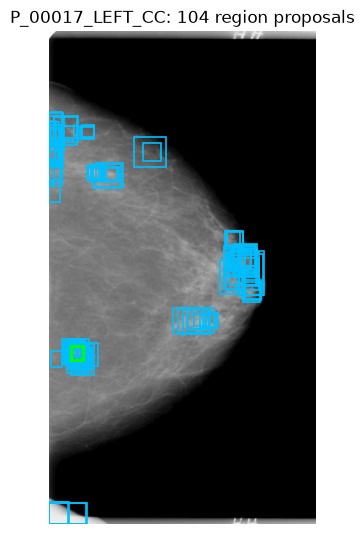

predict:   0%|          | 0/1 [00:00<?, ?it/s]

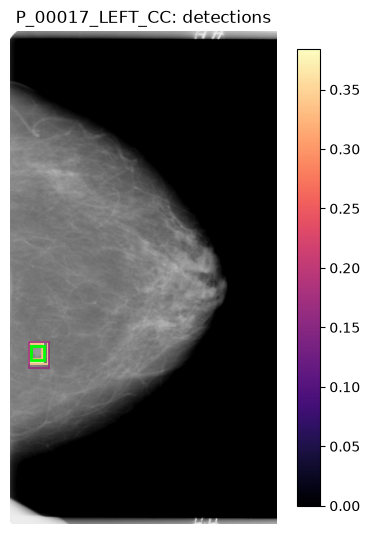

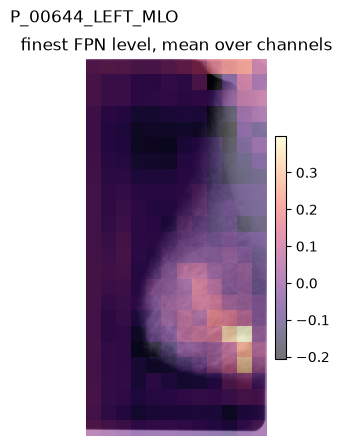

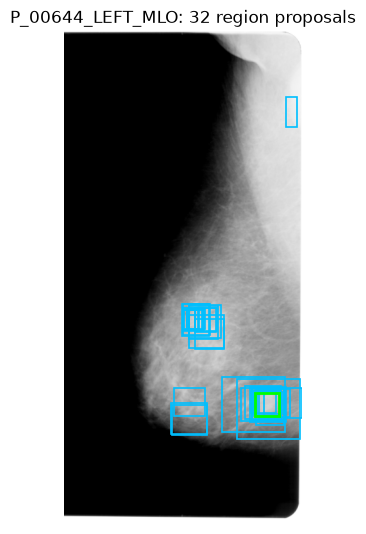

predict:   0%|          | 0/1 [00:00<?, ?it/s]

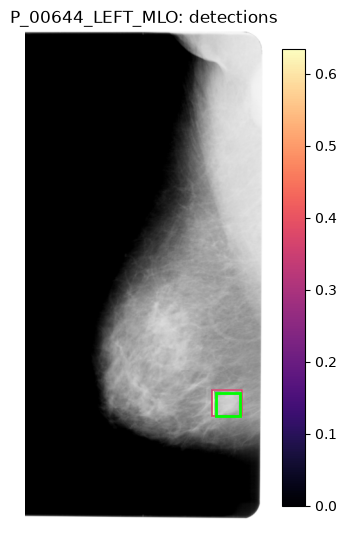

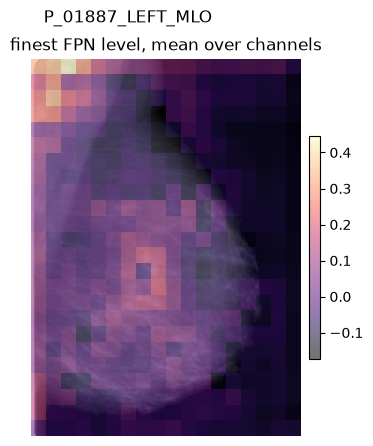

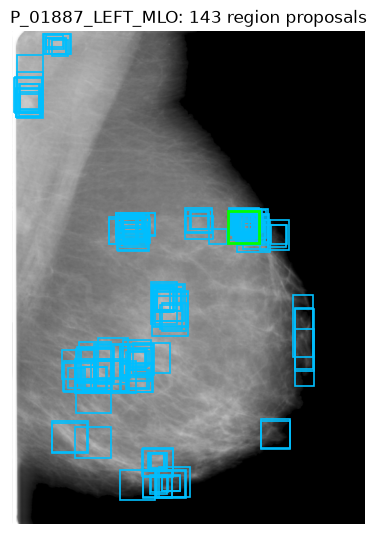

predict:   0%|          | 0/1 [00:00<?, ?it/s]

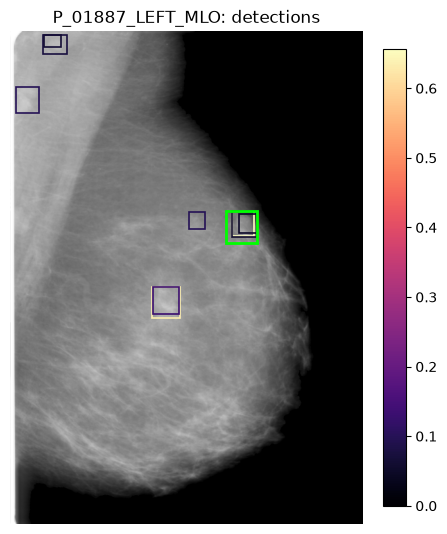

In [ ]:
# Block 14
# What Faster R-CNN sees on held-out mammograms: the proposals its RPN offers the second stage,
# the finest FPN level it reads, and the detections it keeps
scorer = FasterRCNN(config.fold_model_path("faster_rcnn", LESION_TYPE, config.VAL_FOLD))
scorer.load()

val_fold_df = trainval_df[trainval_df["fold"] == config.VAL_FOLD].reset_index(drop=True)

for index in np.linspace(0, len(val_fold_df) - 1, 3, dtype=int):
    row = val_fold_df.iloc[index]
    name = utility.mammogram_id(row.full_image)

    image, gt_boxes, _, proposals, activation = scorer.proposals(row)

    utility.plot_heatmaps(image, [(activation, "finest FPN level, mean over channels")], name)
    utility.plot_boxes_by_score(image, proposals, None, gt_boxes, f"{name}: {len(proposals)} region proposals")

    entry = scorer.predict_raw(val_fold_df.iloc[[index]], score_threshold=config.FASTER_RCNN_SCORE_THRESHOLD)[0]
    utility.plot_boxes_by_score(image, entry["boxes"], entry["scores"], gt_boxes, f"{name}: detections")